In [2]:
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

In [3]:
DATA_PATH = Path("../data/raw")

class_names = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]

print("Dataset exists:", DATA_PATH.exists())
print("Training exists:", (DATA_PATH / "Train").exists())
print("Validation exists:", (DATA_PATH / "Val").exists())

Dataset exists: True
Training exists: True
Validation exists: True


In [4]:
for split in ["Train", "Val"]:
    print("\n", split)

    for name in class_names:
        folder = DATA_PATH / split / name / "images"

        images = list(folder.glob("*.jpg"))

        print(name, ":", len(images))


 Train
Glioma : 1153
Meningioma : 1449
No Tumor : 711
Pituitary : 1424

 Val
Glioma : 136
Meningioma : 140
No Tumor : 100
Pituitary : 136


In [5]:
for name in class_names:
    labels_folder = DATA_PATH / "Train" / name / "labels"

    ids = []

    for file in labels_folder.glob("*.txt"):
        for line in file.read_text().splitlines():
            parts = line.split()

            if len(parts) == 5:
                ids.append(parts[0])

    print(name, ":", dict(Counter(ids)))

Glioma : {'0': 1347, '3': 152, '1': 3}
Meningioma : {'1': 1478, '3': 103, '0': 2}
No Tumor : {'2': 711}
Pituitary : {'3': 1520, '1': 1}


In [7]:
def show_boxes(image_path):
    image_path = Path(image_path)

    label_path = (
        image_path.parent.parent
        / "labels"
        / (image_path.stem + ".txt")
    )

    image = Image.open(image_path).convert("RGB")

    draw = ImageDraw.Draw(image)

    w, h = image.size

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()

            if len(parts) != 5:
                continue

            cls, x, y, bw, bh = map(float, parts)

            x1 = (x - bw / 2) * w
            y1 = (y - bh / 2) * h
            x2 = (x + bw / 2) * w
            y2 = (y + bh / 2) * h

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=3
            )

            draw.text(
                (x1, y1),
                str(int(cls)),
                fill="yellow"
            )

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

Glioma


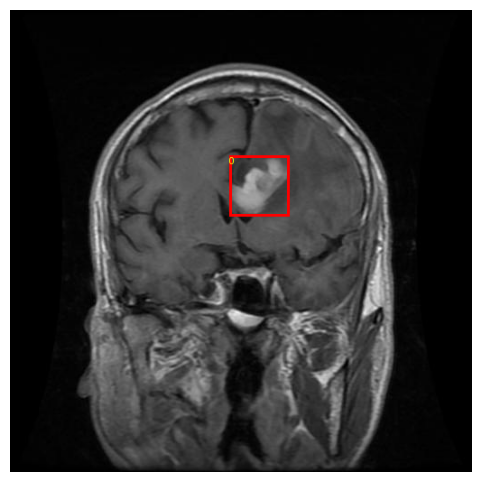

Meningioma


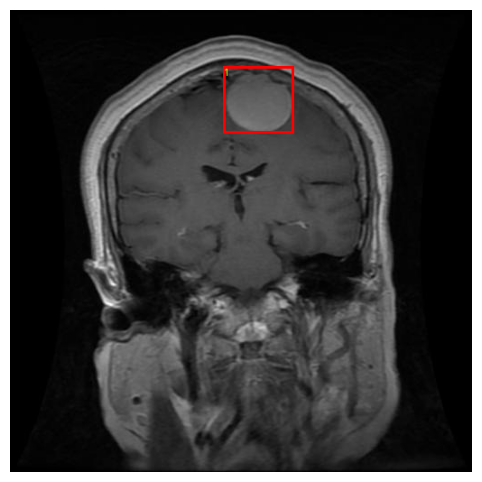

No Tumor


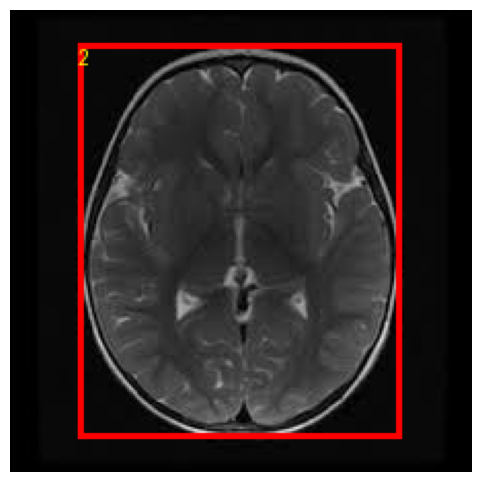

Pituitary


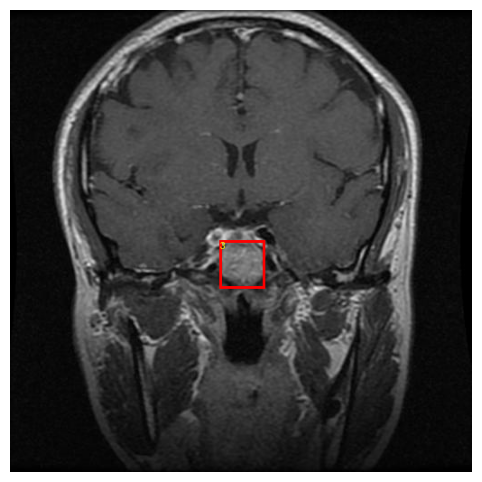

In [9]:
for name in class_names:
    folder = DATA_PATH / "Train" / name / "images"

    image_path = next(folder.glob("*.jpg"))

    print(name)
    show_boxes(image_path)

In [10]:
train_df = pd.read_csv("../data/processed/train.csv")
val_df = pd.read_csv("../data/processed/val.csv")

train_df["image"] = train_df["image"].str.replace(
    "/raw/train/", "/raw/Train/", regex=False
)

print("Train:", len(train_df))
print("Validation:", len(val_df))

Train: 4263
Validation: 512


In [12]:
ANNOTATIONS_VERIFIED = True

In [13]:
import shutil

if not ANNOTATIONS_VERIFIED:
    raise ValueError("Check annotations before preparing YOLO data!")

YOLO_PATH = Path("../data/yolo")

yolo_classes = {
    "Glioma": 0,
    "Meningioma": 1,
    "Pituitary": 2
}

for split, table in [("train", train_df), ("val", val_df)]:

    image_folder = YOLO_PATH / "images" / split
    label_folder = YOLO_PATH / "labels" / split

    image_folder.mkdir(parents=True, exist_ok=True)
    label_folder.mkdir(parents=True, exist_ok=True)

    for _, row in table.iterrows():

        image_path = Path(row["image"])
        category = row["class"]

        old_label = (
            image_path.parent.parent
            / "labels"
            / (image_path.stem + ".txt")
        )

        if not image_path.exists():
            raise FileNotFoundError(image_path)

        if category != "No Tumor" and not old_label.exists():
            raise FileNotFoundError(old_label)

        new_name = category.replace(" ", "_") + "_" + image_path.name

        new_image = image_folder / new_name
        new_label = label_folder / (Path(new_name).stem + ".txt")

        lines = []

        if category != "No Tumor":
            for line in old_label.read_text().splitlines():

                parts = line.split()

                if not parts:
                    continue

                if len(parts) != 5:
                    raise ValueError(f"Invalid label: {old_label}")

                coords = list(map(float, parts[1:]))

                if not all(0 <= v <= 1 for v in coords):
                    raise ValueError(f"Invalid coordinates: {old_label}")

                if coords[2] <= 0 or coords[3] <= 0:
                    raise ValueError(f"Invalid box size: {old_label}")

                new_id = yolo_classes[category]

                lines.append(
                    str(new_id) + " " + " ".join(parts[1:])
                )

        shutil.copy2(image_path, new_image)
        new_label.write_text("\n".join(lines))

print("YOLO dataset created!")

YOLO dataset created!


In [14]:
yaml_text = f"""
path: {YOLO_PATH.resolve()}
train: images/train
val: images/val

names:
  0: Glioma
  1: Meningioma
  2: Pituitary
"""

(YOLO_PATH / "data.yaml").write_text(yaml_text)

print("data.yaml created!")

data.yaml created!


In [15]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: NVIDIA RTX 2000 Ada Generation Laptop GPU


In [17]:
from ultralytics import YOLO

yolo_model = YOLO("yolov8n.pt")

print("YOLOv8 loaded!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLOv8 loaded!


In [19]:
import torch
from pathlib import Path
from ultralytics import YOLO

YOLO_PATH = Path("../data/yolo")
yolo_model = YOLO("yolov8n.pt")

if not torch.cuda.is_available():
    raise RuntimeError("PyTorch GPU is not available!")

results = yolo_model.train(
    data=str((YOLO_PATH / "data.yaml").resolve()),
    epochs=20,
    imgsz=512,
    batch=8,
    device=0,
    workers=0,
    project=str(Path("../models/yolo_runs").resolve()),
    name="yolov8n_mri",
    exist_ok=True
)

New https://pypi.org/project/ultralytics/8.4.190 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.184 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX 2000 Ada Generation Laptop GPU, 8188MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/app/data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, 

In [20]:
best_yolo = YOLO(
    "../models/yolo_runs/yolov8n_mri/weights/best.pt"
)

print("Best YOLO model loaded!")

Best YOLO model loaded!
